In [1]:
#| include: false
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib_inline.backend_inline import set_matplotlib_formats

import deck
from deck import BG, BLUE, GREY, NAVY, OCHRE, RULE, TEAL, TEXT

deck.setup()
set_matplotlib_formats("png")

R = json.loads(Path("results/results.json").read_text())
os.chdir("..")  # photo paths in the results are relative to the repository root
CLASSES = R["classes"]
MODELS = {"dense_head": "Dense head", "augmented": "Dense head + augmentation"}
y_true = np.array(R["test_true"])
best = max(MODELS, key=lambda m: R[m]["val_acc"])
pct = lambda x: f"{100 * x:.0f}%"

## A wrong photo match sends a customer the wrong care guide

::: {.col}

[The situation]{.col-title}

- Customers upload a photo of their flower and get a care guide
- Staff choose the right guide **by hand** today
- Goal: pick it **automatically** for roses, sunflowers and tulips

:::

::: {.col}

[The question]{.col-title}

- Given a photo, **which of the three flowers** is it?
- **When can we trust** the answer, and when should staff check it?

:::


## We have only 300 photos to learn from, so the model must reuse prior knowledge

<div class="metrics">
<div class="metric"><div class="num">300</div><div class="label">Training photos<br>100 per flower</div></div>
<div class="metric"><div class="num">60</div><div class="label">Validation photos<br>to choose the model</div></div>
<div class="metric accent"><div class="num">30</div><div class="label">Test photos<br>used once, at the very end</div></div>
</div>

<p class="note">Source: TensorFlow flower photos (Flickr, CC BY 2.0). Every split has the same number of roses, sunflowers and tulips.</p>

## The photos are messy: close-ups, fields and bouquets, 159 to 640 px wide

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


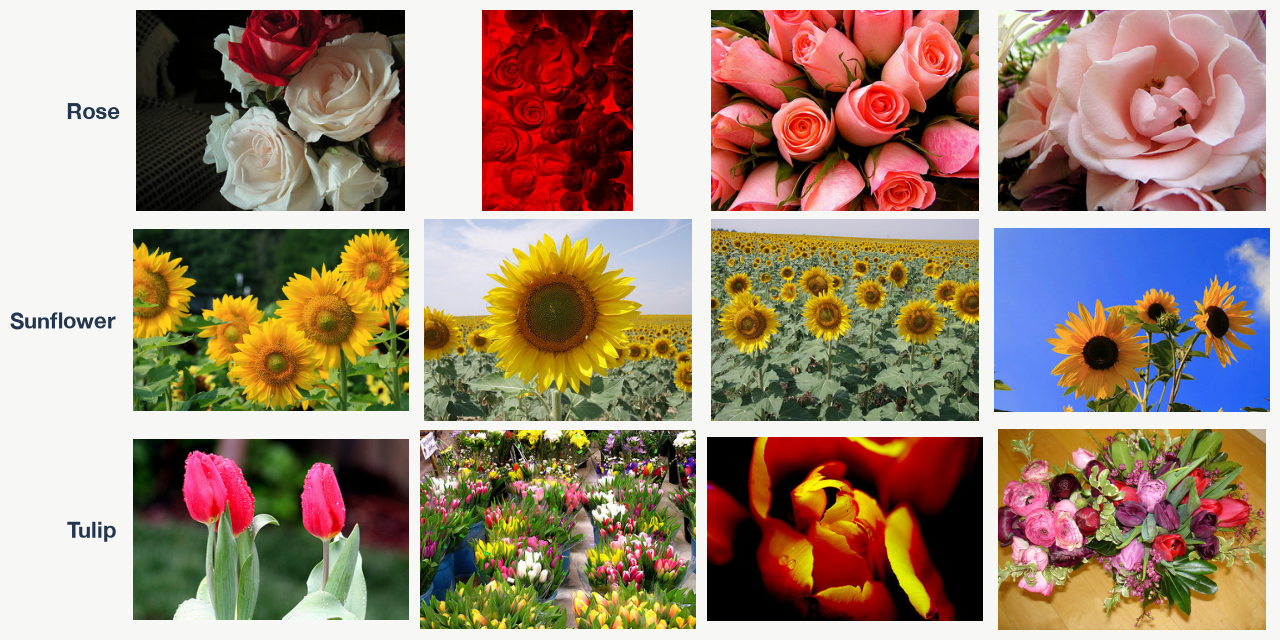

In [2]:
#| fig-alt: Four training photos each of roses, sunflowers and tulips.
fig, axes = plt.subplots(3, 4, figsize=(12.5, 6.2))
for row, flower in enumerate(CLASSES):
    files = sorted(Path("data/train", flower).glob("*.jpg"))[:4]
    for col, file in enumerate(files):
        ax = axes[row, col]
        ax.imshow(plt.imread(file))
        ax.axis("off")
    axes[row, 0].text(-0.06, 0.5, flower.capitalize(), transform=axes[row, 0].transAxes,
                      ha="right", va="center", color=NAVY, fontsize=16, fontweight="semibold")
fig.subplots_adjust(left=0.09, right=1, top=1, bottom=0, wspace=0.04, hspace=0.04)
plt.show()

## Off-the-shelf, MobileNetV2 does not know our flowers: its guesses are scattered

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


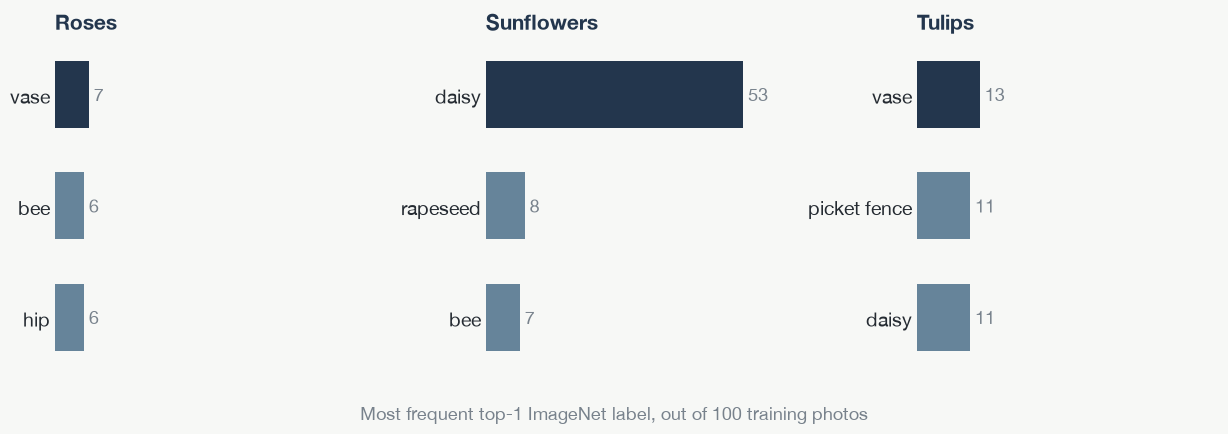

In [3]:
#| fig-alt: Most common ImageNet labels the unmodified network gives to each flower class.
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.4), sharex=True)
for ax, flower in zip(axes, CLASSES):
    labels, counts = zip(*R["imagenet_top1"][flower][:3])
    labels = [l.replace("_", " ") for l in labels]
    colors = [NAVY] + [BLUE] * 2
    ax.barh(labels[::-1], counts[::-1], color=colors[::-1], height=0.6)
    for i, c in enumerate(counts[::-1]):
        ax.text(c + 1, i, str(c), va="center", color=GREY, fontsize=13)
    ax.set_title(f"{flower.capitalize()}s")
    ax.set_xlim(0, 62)
    ax.set_xticks([])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.tick_params(axis="y", labelsize=14, labelcolor=TEXT)
fig.supxlabel("Most frequent top-1 ImageNet label, out of 100 training photos", color=GREY, fontsize=13)
fig.tight_layout()
plt.show()

<p class="note">ImageNet has no rose, sunflower or tulip class. The only strong pattern is sunflowers read as daisies.</p>

## We keep MobileNetV2 as a frozen feature extractor and train only a small classifier

<div class="flow">
<div class="step"><div class="t">Photo</div><div class="d">Resized to 160 × 160 px</div></div>
<div class="arrow">→</div>
<div class="step frozen"><div class="t">MobileNetV2, frozen</div><div class="d">Pretrained on ImageNet. Turns a photo into 1,280 numbers</div></div>
<div class="arrow">→</div>
<div class="step trained"><div class="t">Dense layer, trained</div><div class="d">Learns three outputs: rose, sunflower, tulip</div></div>
</div>

<div class="variants">
<div><span class="k">Model 1: Dense head</span>Trained on features computed once from the photos</div>
<div><span class="k">Model 2: Dense head + augmentation</span>Trained on photos randomly flipped, rotated and zoomed</div>
</div>

In [4]:
def curves(key):
    h = R[key]["history"]
    ep = np.arange(1, len(h["loss"]) + 1)
    fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.6))
    for ax, name, ylabel, ylim in [(a, "loss", "Loss", (0, 1.9)), (b, "accuracy", "Accuracy", (0.3, 1.05))]:
        train, val = np.array(h[name]), np.array(h["val_" + name])
        ax.plot(ep, train, color=BLUE, lw=2.5, label="Training")
        ax.plot(ep, val, color=NAVY, lw=3, label="Validation")
        ax.scatter([ep[-1]], [val[-1]], color=OCHRE, s=90, zorder=5)
        ax.annotate(f"{val[-1]:.0%}" if name == "accuracy" else f"{val[-1]:.2f}", (ep[-1], val[-1]),
                    xytext=(8, -4 if name == "accuracy" else 6), textcoords="offset points", color=NAVY,
                    fontsize=14, fontweight="semibold")
        ax.annotate(f"{train[-1]:.0%}" if name == "accuracy" else f"{train[-1]:.2f}", (ep[-1], train[-1]),
                    xytext=(8, 4 if name == "accuracy" else -14), textcoords="offset points", color=BLUE,
                    fontsize=14, fontweight="semibold")
        ax.set_ylim(*ylim)
        ax.set_xlim(1, ep[-1] + 4)
        ax.set_xlabel("Epoch")
        ax.set_title(ylabel)
        ax.yaxis.grid(True, color=RULE, lw=0.8)
        ax.set_axisbelow(True)
        ax.spines[["left", "bottom"]].set_visible(False)
        if name == "accuracy":
            ax.set_yticks([0.4, 0.6, 0.8, 1.0], ["40%", "60%", "80%", "100%"])
    a.legend(loc="upper right")
    fig.tight_layout()
    plt.show()

## The dense head memorises the training photos but plateaus at 87% on validation

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


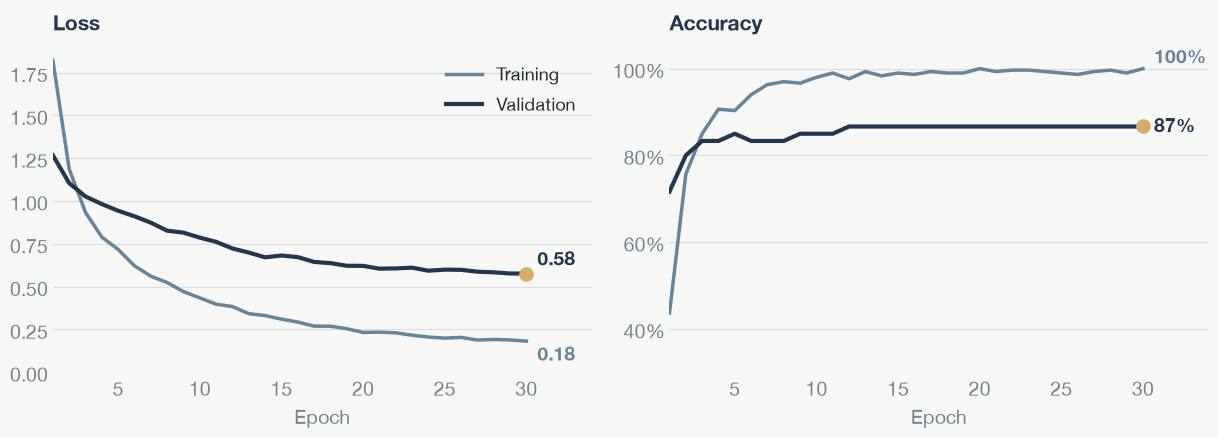

In [5]:
#| fig-alt: Training and validation loss and accuracy of the dense head over 30 epochs.
curves("dense_head")

<p class="note"><strong>Observed:</strong> training accuracy reaches 100%, validation stays near 87%. <strong>Interpretation:</strong> the model overfits a little, as expected with 100 photos per flower.</p>

## Augmentation closes the training–validation gap, but validation accuracy drops to 75%

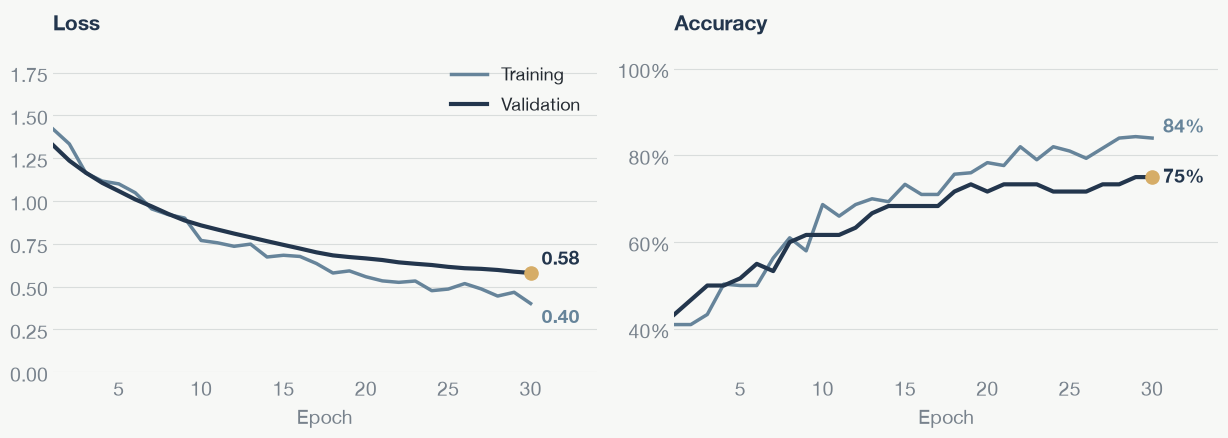

In [6]:
#| fig-alt: Training and validation loss and accuracy of the augmented model over 30 epochs.
curves("augmented")

<p class="note"><strong>Observed:</strong> both curves are still improving after 30 epochs. <strong>Interpretation:</strong> it may need longer training; we did not test that.</p>

## The dense head wins on validation; both models classify 28 of 30 test photos correctly

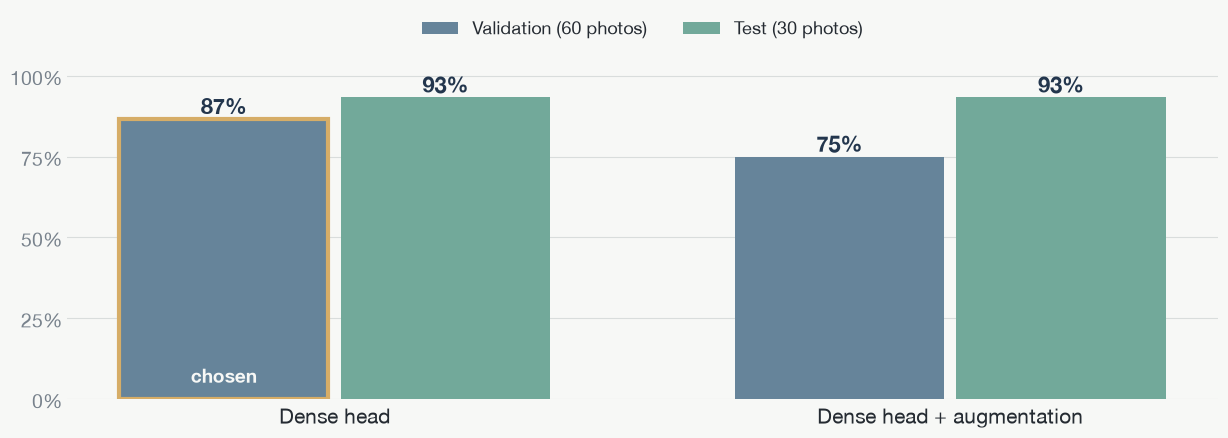

In [7]:
#| fig-alt: Validation and test accuracy of both models as grouped bars.
fig, ax = plt.subplots(figsize=(12.5, 4.6))
x = np.arange(len(MODELS))
w = 0.34
val = [R[m]["val_acc"] for m in MODELS]
test = [R[m]["test_acc"] for m in MODELS]
b1 = ax.bar(x - w / 2 - 0.01, val, w, color=BLUE, label="Validation (60 photos)")
b2 = ax.bar(x + w / 2 + 0.01, test, w, color=TEAL, label="Test (30 photos)")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, pct(bar.get_height()),
                ha="center", color=NAVY, fontsize=16, fontweight="semibold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2)
best_i = list(MODELS).index(best)
ax.text(best_i - w / 2 - 0.01, 0.05, "chosen", ha="center", color=BG, fontsize=14, fontweight="semibold")
b1[best_i].set_edgecolor(OCHRE)
b1[best_i].set_linewidth(3)
ax.set_xticks(x, list(MODELS.values()), fontsize=15, color=TEXT)
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.yaxis.grid(True, color=RULE, lw=0.8)
ax.set_axisbelow(True)
ax.spines[["left", "bottom"]].set_visible(False)
fig.tight_layout()
plt.show()

<p class="note">One photo is worth 3.3 points on the test set and 1.7 points on validation, so a gap of two photos (87% vs 93%) is within noise. We chose the model by validation accuracy only.</p>

## All of the chosen model's errors are sunflowers: two of ten were mistaken for another flower

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


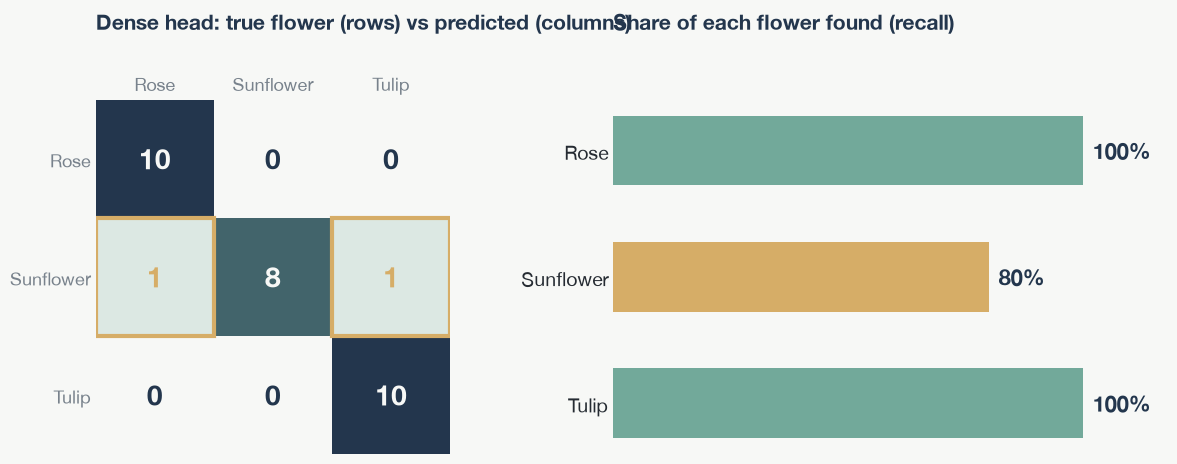

In [8]:
#| fig-alt: Confusion matrix and per-flower recall of the chosen model on the test set.
pred = np.array(R[best]["test_pred"])
cm = np.zeros((3, 3), int)
for t, p in zip(y_true, pred):
    cm[t, p] += 1
recall = cm.diagonal() / cm.sum(1)

fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
a.imshow(cm, cmap=deck.TEAL_MAP, vmin=0, vmax=10)
for i in range(3):
    for j in range(3):
        wrong = i != j and cm[i, j] > 0
        a.text(j, i, cm[i, j], ha="center", va="center", fontsize=20, fontweight="semibold",
               color=BG if cm[i, j] >= 6 else (NAVY if not wrong else OCHRE))
        if wrong:
            a.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=OCHRE, lw=3))
names = [c.capitalize() for c in CLASSES]
a.set_xticks(range(3), names, fontsize=13)
a.set_yticks(range(3), names, fontsize=13)
a.xaxis.tick_top()
a.xaxis.set_label_position("top")
a.spines[:].set_visible(False)

colors = [OCHRE if r < 1 else TEAL for r in recall]
b.barh(names[::-1], recall[::-1], color=colors[::-1], height=0.55)
for i, r in enumerate(recall[::-1]):
    b.text(r + 0.02, i, pct(r), va="center", color=NAVY, fontsize=16, fontweight="semibold")
b.set_xlim(0, 1.18)
b.set_xticks([])
b.spines[["left", "bottom"]].set_visible(False)
b.tick_params(axis="y", labelsize=14, labelcolor=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.88))
for ax, text in [(a, f"{MODELS[best]}: true flower (rows) vs predicted (columns)"), (b, "Share of each flower found (recall)")]:
    fig.text(ax.get_position().x0, 0.97, text, fontsize=15, fontweight="semibold", color=NAVY, va="top")
plt.show()

## The missed sunflowers were not the subject of the photo: a bouquet and a distant garden

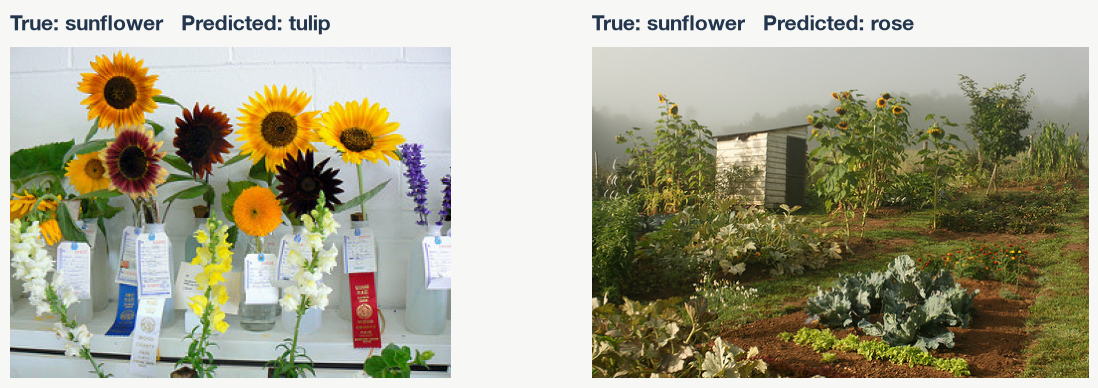

In [9]:
#| fig-alt: The misclassified test photos with true and predicted labels.
wrong = np.where(y_true != np.array(R[best]["test_pred"]))[0]
fig, axes = plt.subplots(1, len(wrong), figsize=(12.5, 4.1))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.set_anchor("N")
    ax.imshow(plt.imread(R["test_files"][i]))
    ax.axis("off")
    ax.set_title(f"True: {CLASSES[y_true[i]]}   Predicted: {CLASSES[R[best]['test_pred'][i]]}",
                 fontsize=15, color=NAVY, loc="left")
fig.tight_layout()
plt.show()

<p class="note"><strong>Observed:</strong> in one photo sunflowers sit among other flowers in vases; in the other they are small and far away. <strong>Interpretation:</strong> with only two errors this is a hint, not a proven pattern.</p>

## A frozen MobileNetV2 with one dense layer is a strong start, with clear limits

:::: {.two-col}
::: {.col}

[What we found]{.col-title}

- **28 of 30** test photos are classified correctly (93%)
- Augmentation did **not** beat the plain dense head on validation
- Both errors were sunflowers in cluttered scenes

:::

::: {.col}

[What to keep in mind]{.col-title}

- 30 test photos is **few**: one photo moves the result by 3.3 points
- Only three flowers are covered; a daisy still gets one of them
- Next: show the covered flowers on the website, let staff review doubtful photos, add more cluttered sunflower examples

:::
::::

## Try the model yourself: upload a flower photo and see what it predicts

[great-flower-app.streamlit.app](https://great-flower-app.streamlit.app/){.cta}

[Upload a rose, sunflower or tulip photo and compare the models. Try a cluttered sunflower photo to see where they struggle.]{.note}
